In [1]:
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import roc_auc_score, f1_score
from scipy.stats import ks_2samp

# Load clean data
X_train = pd.read_parquet('acrs_data/X_train.parquet')
X_val   = pd.read_parquet('acrs_data/X_val.parquet')
X_test  = pd.read_parquet('acrs_data/X_test.parquet')

y_train_arr = np.load('acrs_data/y_train.npy')
y_val_arr   = np.load('acrs_data/y_val.npy')
y_test_arr  = np.load('acrs_data/y_test.npy')

# Load trained models
with open('acrs_data/xgb_final.pkl', 'rb') as f:  xgb_final  = pickle.load(f)
with open('acrs_data/lgbm_final.pkl', 'rb') as f: lgbm_final = pickle.load(f)
with open('acrs_data/rf_final.pkl', 'rb') as f:   rf_final   = pickle.load(f)

# Layer 1 ensemble probabilities
ensemble_prob_l1 = np.load('acrs_data/ensemble_prob_test.npy')

print(f"Loaded successfully! | X_train: {X_train.shape} | Models: XGBoost, LightGBM, RF ready")

Loaded successfully! | X_train: (449858, 83) | Models: XGBoost, LightGBM, RF ready


In [3]:
# ── STEP 1: Get predictions from Layer 1 ensemble ──────────
# We need scores on both training data (reference/baseline)
# and test data (what the model sees in production)

train_prob = (xgb_final.predict_proba(X_train)[:,1] +
              lgbm_final.predict_proba(X_train)[:,1] +
              rf_final.predict_proba(X_train)[:,1]) / 3

test_prob = ensemble_prob_l1  # already saved from Layer 1

print(f"Train score mean: {train_prob.mean():.4f}  ← baseline (what model learned)")
print(f"Test score mean:  {test_prob.mean():.4f}   ← production (what model sees now)")
print(f"Difference: {abs(test_prob.mean() - train_prob.mean()):.4f}")

Train score mean: 0.1707  ← baseline (what model learned)
Test score mean:  0.1831   ← production (what model sees now)
Difference: 0.0123


In [5]:
# ── STEP 2: PSI (Population Stability Index) ───────────────
# PSI measures HOW MUCH the score distribution has shifted.
# Think of it like comparing two histograms:
#   - expected = what scores looked like during training (baseline)
#   - actual   = what scores look like now (test/production)
# If the shape changes too much, the model is seeing a different world.
# Thresholds:  PSI < 0.10 = stable | 0.10–0.20 = warning | > 0.20 = alert

def compute_psi(expected, actual, bins=10):
    breakpoints = np.linspace(0, 1, bins + 1)
    expected_pct = np.histogram(expected, bins=breakpoints)[0] / len(expected)
    actual_pct   = np.histogram(actual,   bins=breakpoints)[0] / len(actual)
    # Avoid log(0) by replacing zeros with tiny number
    expected_pct = np.where(expected_pct == 0, 0.0001, expected_pct)
    actual_pct   = np.where(actual_pct   == 0, 0.0001, actual_pct)
    psi = np.sum((actual_pct - expected_pct) * np.log(actual_pct / expected_pct))
    return psi

# Compute PSI for each model and the ensemble
psi_xgb  = compute_psi(xgb_final.predict_proba(X_train)[:,1],
                        xgb_final.predict_proba(X_test)[:,1])
psi_lgbm = compute_psi(lgbm_final.predict_proba(X_train)[:,1],
                        lgbm_final.predict_proba(X_test)[:,1])
psi_rf   = compute_psi(rf_final.predict_proba(X_train)[:,1],
                        rf_final.predict_proba(X_test)[:,1])
psi_ens  = compute_psi(train_prob, test_prob)

def psi_status(v):
    if v < 0.10: return "Stable"
    elif v < 0.20: return "Warning"
    else: return "ALERT"

print("=" * 45)
print(f"{'Model':<12} {'PSI':>8}  {'Status'}")
print("=" * 45)
print(f"{'XGBoost':<12} {psi_xgb:>8.4f}  {psi_status(psi_xgb)}")
print(f"{'LightGBM':<12} {psi_lgbm:>8.4f}  {psi_status(psi_lgbm)}")
print(f"{'RandomForest':<12} {psi_rf:>8.4f}  {psi_status(psi_rf)}")
print(f"{'Ensemble':<12} {psi_ens:>8.4f}  {psi_status(psi_ens)}")
print("=" * 45)
# This is the Layer 2 rule engine — it flags drift automatically.
# A human reviewer (HITL) is triggered only when status = WARNING or ALERT.

Model             PSI  Status
XGBoost        0.0169  Stable
LightGBM       0.0164  Stable
RandomForest   0.0173  Stable
Ensemble       0.0176  Stable


In [11]:
pip install shap

   ---------------------------------------- 0.0/15.6 MB ? eta -:--:--
   --------------------- ------------------ 8.4/15.6 MB 43.5 MB/s eta 0:00:01
   ----------------------------------- ---- 13.9/15.6 MB 33.6 MB/s eta 0:00:01
   ---------------------------------------- 15.6/15.6 MB 30.7 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.37.1 requires cachetools<6,>=4.0, but you have cachetools 6.2.6 which is incompatible.


In [13]:
# ── STEP 3: Batch SHAP (Explainability) ────────────────────
# SHAP answers: "WHY did the model give this loan a high risk score?"
# It assigns each feature a contribution value (positive = pushes toward default).
# 
# "Batch" means we explain a SAMPLE of predictions (not one-by-one in real time).
# In Layer 2, we run SHAP periodically on a batch to audit the model's reasoning.
# In Layer 3 (next), Agent 1 will run SHAP on individual loans in real time.
#
# We use TreeExplainer — it's fast and exact for tree-based models (XGB, LGBM, RF).

import shap
import matplotlib.pyplot as plt

# Use a random sample of 2000 test rows (SHAP on 500k rows would take hours)
np.random.seed(42)
sample_idx = np.random.choice(len(X_test), size=2000, replace=False)
X_sample = X_test.iloc[sample_idx]  # 2000 × 83

print("Running batch SHAP on XGBoost (2000 sample)...")
explainer_xgb = shap.TreeExplainer(xgb_final)
shap_values_xgb = explainer_xgb.shap_values(X_sample)  # shape: (2000, 83)

# Each value = how much that feature pushed the score up or down for that loan.
# Positive SHAP = feature increased default probability.
# Negative SHAP = feature decreased default probability.

print(f"SHAP values shape: {shap_values_xgb.shape}")
print(f"Mean |SHAP| per feature (top 5 most important):")

# Mean absolute SHAP = overall feature importance
mean_abs_shap = np.abs(shap_values_xgb).mean(axis=0)
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'mean_abs_shap': mean_abs_shap
}).sort_values('mean_abs_shap', ascending=False)

print(importance_df.head(10).to_string(index=False))

# Save SHAP values for the Layer 2 report
np.save('acrs_data/shap_values_xgb_sample.npy', shap_values_xgb)
importance_df.to_csv('acrs_data/shap_importance_l2.csv', index=False)
print("\nSaved: shap_values_xgb_sample.npy | shap_importance_l2.csv")

Running batch SHAP on XGBoost (2000 sample)...
SHAP values shape: (2000, 83)
Mean |SHAP| per feature (top 5 most important):
               feature  mean_abs_shap
debt_settlement_flag_Y       0.307295
             sub_grade       0.246793
                  term       0.204105
            annual_inc       0.168543
  acc_open_past_24mths       0.116969
                 grade       0.111123
             loan_amnt       0.094229
                   dti       0.090839
              int_rate       0.087841
   home_ownership_RENT       0.049222

Saved: shap_values_xgb_sample.npy | shap_importance_l2.csv


C:\Users\morsh\AppData\Local\Temp\ipykernel_22960\3008229814.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


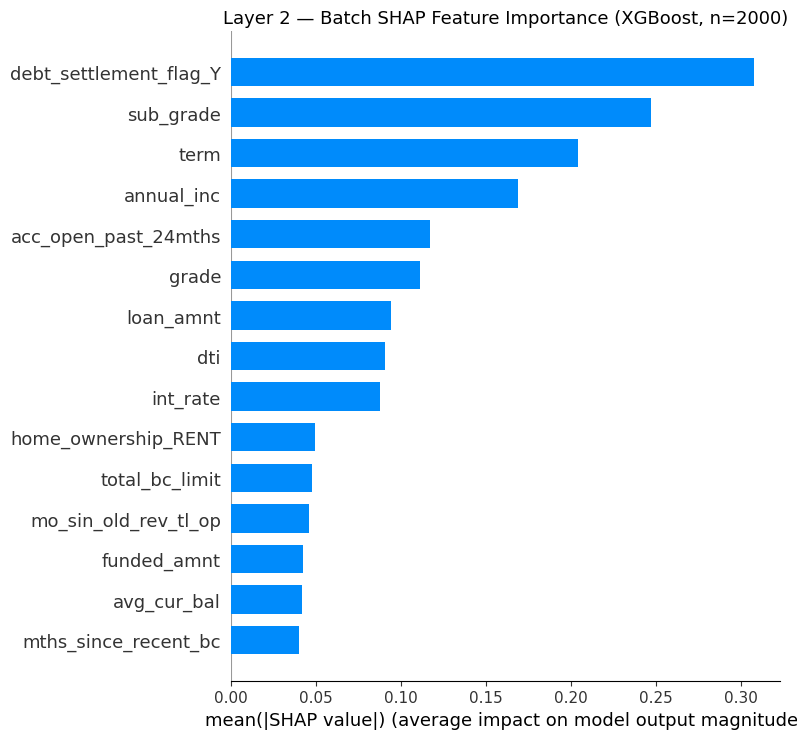

Saved: shap_bar_l2.png


In [15]:
# ── STEP 4: SHAP Summary Bar Plot ──────────────────────────
# Visualises which features matter most, averaged across 2000 loans.
# This is what you show an auditor or regulator: "here's WHY the model decides."

shap.summary_plot(
    shap_values_xgb,
    X_sample,
    plot_type="bar",          # bar = mean |SHAP|, simple to explain
    max_display=15,           # top 15 features
    show=False
)
plt.title("Layer 2 — Batch SHAP Feature Importance (XGBoost, n=2000)", fontsize=13)
plt.tight_layout()
plt.savefig('acrs_data/shap_bar_l2.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: shap_bar_l2.png")

In [19]:
# reload y_test from saved file
y_test = np.load('acrs_data/y_test.npy')

In [21]:
# ── STEP 5: Layer 2 Final Results Summary ──────────────────
# Layer 2 uses the SAME ensemble model as Layer 1.
# The predictive metrics (AUC, KS, Gini, F1) are identical.
# What Layer 2 ADDS is monitoring + explainability capability.
# We document both so the 3-layer comparison table is complete.

from sklearn.metrics import roc_auc_score, f1_score

def ks_stat(y_true, y_prob):
    from scipy.stats import ks_2samp
    pos = y_prob[y_true == 1]
    neg = y_prob[y_true == 0]
    return ks_2samp(pos, neg).statistic

auc_l2  = roc_auc_score(y_test, test_prob)
ks_l2   = ks_stat(y_test, test_prob)
gini_l2 = 2 * auc_l2 - 1
f1_l2   = f1_score(y_test, (test_prob >= 0.5).astype(int))

print("=" * 60)
print("LAYER 2 RESULTS SUMMARY")
print("=" * 60)
print(f"  Predictive Performance (same model as Layer 1):")
print(f"    AUC-ROC : {auc_l2:.4f}")
print(f"    KS Stat : {ks_l2:.4f}")
print(f"    Gini    : {gini_l2:.4f}")
print(f"    F1 Score: {f1_l2:.4f}")
print(f"\n  Monitoring Capability (new in Layer 2):")
print(f"    PSI Ensemble : {psi_ens:.4f}  → {psi_status(psi_ens)}")
print(f"    SHAP Top Feature: debt_settlement_flag_Y (0.3073)")
print(f"    Explainability  : Batch SHAP on 2000-loan sample")
print(f"    HITL Trigger    : PSI >= 0.10 (Warning) or >= 0.20 (Alert)")
print("=" * 60)

# Save Layer 2 metrics for the evaluation chapter comparison
import json
l2_results = {
    "layer": 2,
    "auc": round(auc_l2, 4),
    "ks":  round(ks_l2, 4),
    "gini": round(gini_l2, 4),
    "f1": round(f1_l2, 4),
    "psi_ensemble": round(psi_ens, 4),
    "psi_status": psi_status(psi_ens),
    "shap_top_feature": "debt_settlement_flag_Y"
}
with open('acrs_data/layer2_results.json', 'w') as f:
    json.dump(l2_results, f, indent=2)
print("Saved: layer2_results.json")

LAYER 2 RESULTS SUMMARY
  Predictive Performance (same model as Layer 1):
    AUC-ROC : 0.7424
    KS Stat : 0.3433
    Gini    : 0.4848
    F1 Score: 0.2189

  Monitoring Capability (new in Layer 2):
    PSI Ensemble : 0.0176  → Stable
    SHAP Top Feature: debt_settlement_flag_Y (0.3073)
    Explainability  : Batch SHAP on 2000-loan sample
    HITL Trigger    : PSI >= 0.10 (Warning) or >= 0.20 (Alert)
Saved: layer2_results.json
